# Lecture 20, Predictor selection and nonlinear regression

> Which of the many GCM variables should enter a downscaling model, and when does a neural network earn its place?

Lecture 19 fitted a multiple linear regression

$$y_t = \beta_0 + \beta_1 x_{t1} + \dots + \beta_p x_{tp} + \varepsilon_t ,$$

with $y_t$ the local predictand (for example monthly rainfall, mm day$^{-1}$), $x_{tj}$ the $j$-th large-scale predictor and $\varepsilon_t$ the error. It assumed that the predictors had already been chosen. In practice a reanalysis or GCM offers dozens of candidates: humidity, geopotential height, winds and temperature at several pressure levels, at several grid cells. Meanwhile a station record may hold only 30 years of monthly data, 360 values. This lecture asks two questions that follow.

- **Which predictors should we keep?** Too many predictors fit the noise of the calibration period and fail in the validation period.
- **What if the relation is not a straight line?** Rainfall saturates, switches on above a humidity threshold, or depends on two predictors jointly. A model with a nonlinear form may then do better.

By the end of this lecture you should be able to:

1. explain why many candidate predictors, few observations and correlated predictors cause **overfitting** and unstable coefficients;
2. run **stepwise regression** with AIC or BIC (formulas derived), and state its limits;
3. write the **LASSO** objective, derive that for one standardised predictor its solution is the **soft threshold** of the least-squares coefficient, implement **coordinate descent** and **k-fold cross-validation** in numpy, and read a regularisation path;
4. say why predictors must be standardised and how LASSO differs from ridge regression;
5. derive the forward pass and **backpropagation** of a one-hidden-layer neural network, implement it from scratch, and control overfitting by **early stopping**;
6. judge honestly when a neural network is worth using for downscaling, and why extrapolation to a warmer climate is its main risk.

All data in this lecture are **synthetic** (generated by a recipe shown below), so that we know the truth. A companion Excel workbook
(`data/downscaling/lec20/lec20_worked_examples.xlsx`, Section 8) repeats the key calculations with live formulas.

In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas matplotlib scipy

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN, RED, GREY = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#666666"

FOLDER = "data/downscaling/lec20"
URL = "https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/data/downscaling/lec20/"

def make_data(seed=524, n_train=120, n_test=120, p=20, rho=0.7, noise=0.8):
    """Recipe of the synthetic data: p standardised predictors with AR(1)-type correlation rho**|i-j|;
    only P03, P08 and P14 matter, and P14 acts nonlinearly (saturating)."""
    rng = np.random.default_rng(seed)
    n = n_train + n_test
    X = np.zeros((n, p)); X[:, 0] = rng.standard_normal(n)
    for j in range(1, p):
        X[:, j] = rho * X[:, j-1] + np.sqrt(1 - rho**2) * rng.standard_normal(n)
    X = X.round(3)
    f = 1.5 * X[:, 2] - 1.0 * X[:, 7] + 2.0 * np.tanh(1.5 * X[:, 13]) + 0.3 * X[:, 13]
    y = (f + noise * rng.standard_normal(n)).round(3)
    df = pd.DataFrame(X, columns=["P%02d" % (j + 1) for j in range(p)]); df["y"] = y
    df["split"] = ["train"] * n_train + ["test"] * n_test
    return df

def read_csv(name):
    """Local file first, then GitHub (for Colab)."""
    for src in (os.path.join(FOLDER, name), URL + name):
        try:
            return pd.read_csv(src)
        except Exception:
            pass
    return None

df = read_csv("lec20_synthetic_20_predictors.csv")
if df is None:
    df = make_data()          # the CSV is exactly this output
P = [c for c in df.columns if c.startswith("P")]
tr, te = df[df.split == "train"], df[df.split == "test"]
Xtr, ytr, Xte, yte = tr[P].values, tr["y"].values, te[P].values, te["y"].values
n, p = Xtr.shape
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b))**2)))
print(f"{n} training months, {len(yte)} test months, {p} candidate predictors")
print("sd of y in test period: %.2f   (noise sd built into the data: 0.80)" % yte.std())

120 training months, 120 test months, 20 candidate predictors
sd of y in test period: 2.45   (noise sd built into the data: 0.80)


**The data (synthetic).** Think of $y$ as a monthly rainfall anomaly (mm day$^{-1}$) at a station in the Western Ghats, and of the 20 columns `P01`..`P20` as standardised large-scale anomalies (specific humidity, 850 hPa wind, geopotential height, ...) from a reanalysis. We use 120 months (10 years) for calibration and the following 120 months as an independent test period. Neighbouring columns are correlated ($0.7^{|i-j|}$), as real predictors are. Only three columns carry information:

$$y = 1.5\,P_{03} - 1.0\,P_{08} + 2\tanh(1.5\,P_{14}) + 0.3\,P_{14} + \varepsilon,\qquad \varepsilon\sim N(0,0.8^2).$$

`P14` acts nonlinearly: it saturates for large values. The best any model can do on the test period is an RMSE of 0.8, the noise. **To use real data**, replace the CSV by a table with one row per month, your predictors as columns, a column `y` and a column `split`; nothing else in the notebook changes.

# 1) Why predictor selection matters

With $n$ observations and $p$ predictors, least squares estimates $p+1$ numbers. Three things go wrong as $p$ grows.

- **Overfitting.** The calibration error can only fall when a predictor is added, even a useless one: the extra column lets the line chase the noise. The error in a *new* period typically rises again. A model with $p=n-1$ predictors reproduces the calibration data exactly and predicts nothing.
- **Multicollinearity.** If two predictors are strongly correlated (geopotential height at 500 and 700 hPa, say), the data cannot tell which one carries the signal. The two coefficients become large with opposite signs and highly uncertain, although their sum is well determined. Then a small change in the calibration period changes the model a lot.
- **Physical meaning.** A model with 20 coefficients cannot be checked against what we know about the rainfall mechanism. A model with three can.

The experiment below starts from an ordinary least-squares (OLS) model with the three informative predictors (we know them here) and then adds the 17 useless ones in random order, 200 times, averaging the RMSE in the calibration and test periods.

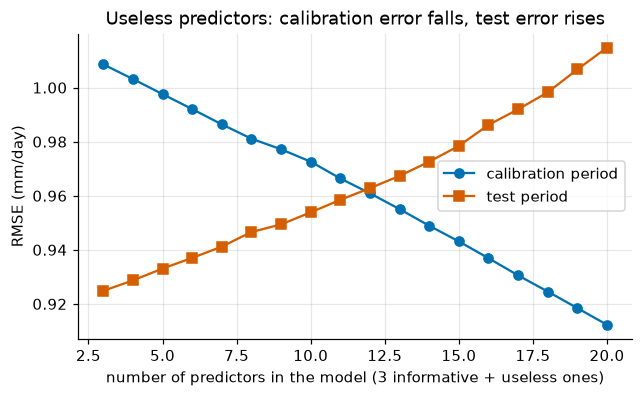

3 predictors: calibration RMSE 1.01, test RMSE 0.92
20 predictors: calibration RMSE 0.91, test RMSE 1.01


In [3]:
def ols(X, y):
    """Least squares with intercept: returns [b0, b1, ..., bk] (Lecture 19)."""
    A = np.c_[np.ones(len(y)), X]
    return np.linalg.lstsq(A, y, rcond=None)[0]
def predict_ols(b, X):
    return b[0] + X @ b[1:]

rng = np.random.default_rng(0)
ks = np.arange(3, p + 1)
true_idx = [2, 7, 13]; others = [j for j in range(p) if j not in true_idx]
e_tr, e_te = np.zeros(len(ks)), np.zeros(len(ks))
reps = 200
for _ in range(reps):
    order = np.r_[true_idx, rng.permutation(others)]
    for i, k in enumerate(ks):
        cols = order[:k]
        b = ols(Xtr[:, cols], ytr)
        e_tr[i] += rmse(predict_ols(b, Xtr[:, cols]), ytr) / reps
        e_te[i] += rmse(predict_ols(b, Xte[:, cols]), yte) / reps

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(ks, e_tr, "o-", color=BLUE, label="calibration period")
ax.plot(ks, e_te, "s-", color=RED, label="test period")
ax.set_xlabel("number of predictors in the model (3 informative + useless ones)"); ax.set_ylabel("RMSE (mm/day)")
ax.set_title("Useless predictors: calibration error falls, test error rises"); ax.legend()
plt.show()
print("3 predictors: calibration RMSE %.2f, test RMSE %.2f" % (e_tr[0], e_te[0]))
print("20 predictors: calibration RMSE %.2f, test RMSE %.2f" % (e_tr[-1], e_te[-1]))

Every useless predictor lowers the calibration RMSE a little, because the extra column can absorb some of the noise, but raises the test RMSE. The widening gap between the two curves is the optimism of the calibration fit. Predictor selection is the attempt to keep the helpful columns and drop the rest.

# 2) Stepwise regression

**The idea.** Search over subsets of predictors greedily, adding or removing one predictor at a time, and stop when no step improves a selection criterion. All $2^{p}$ subsets are too many to fit for $p=20$ (over a million), so the greedy search compromises.

- **Forward selection:** start with the intercept only; at each step add the predictor that improves the criterion most; stop when none does.
- **Backward elimination:** start with all predictors; at each step remove the one whose removal improves the criterion most.
- **Both directions:** forward steps, but after each addition also test whether any included predictor can now be dropped.

**Selection criteria.**

*p-value.* Each candidate coefficient has a $t$ statistic $t_j=\hat\beta_j/\mathrm{se}(\hat\beta_j)$ and a p-value (Lecture 19). A predictor enters if its smallest p-value is below $\alpha_{\text{enter}}$ and leaves if its p-value exceeds $\alpha_{\text{remove}}\ge\alpha_{\text{enter}}$ (the inequality prevents a predictor from entering and leaving forever). The thresholds are choices of the analyst, often looser than 0.05.

*AIC and BIC.* Suppose the errors are Gaussian with variance $\sigma^2$. With $k$ fitted regression parameters (intercept included) the maximised log-likelihood is obtained by inserting $\hat\sigma^2 = \mathrm{SSE}/n$, where $\mathrm{SSE}=\sum_t (y_t-\hat y_t)^2$:

$$\ln L_{\max} = -\frac{n}{2}\Big[\ln\!\big(2\pi\,\mathrm{SSE}/n\big)+1\Big].$$

A criterion that rewards fit but charges a price per parameter is

$$\boxed{\mathrm{AIC} = -2\ln L_{\max}+2k = n\ln\frac{\mathrm{SSE}}{n}+2k+\text{const},\qquad \mathrm{BIC} = n\ln\frac{\mathrm{SSE}}{n}+k\ln n+\text{const}.}$$

The constant is the same for every model fitted to the same data, so we drop it; the model with the **smallest** value wins. (The error variance is one more parameter in every model, so counting it changes all AIC values by 2 and nothing else.) Adding a predictor lowers the criterion only if the fit gain $n\ln(\mathrm{SSE}_{\text{old}}/\mathrm{SSE}_{\text{new}})$ exceeds the penalty, $2$ for AIC and $\ln n$ for BIC. For $n=120$, $\ln n = 4.8$: BIC demands a SSE reduction of about $4\%$ per predictor and AIC about $1.7\%$, so **BIC picks smaller models**. Sanity check with a quick number: $n=120$ and a predictor that reduces SSE by 3% gives $120\ln(1/0.97)=3.65$, which is above 2 (AIC keeps it) and below 4.8 (BIC rejects it). The spreadsheet in Section 8 evaluates both criteria on LINEST output.

Predictors are standardised first (Section 3 explains why; for OLS it only changes the scale of the coefficients, not the selection).

In [4]:
mu, sd = Xtr.mean(0), Xtr.std(0)            # training-period statistics only
Ztr, Zte = (Xtr - mu) / sd, (Xte - mu) / sd

def sse(X, y):
    if X.shape[1] == 0:
        return ((y - y.mean())**2).sum()
    b = ols(X, y); return ((y - predict_ols(b, X))**2).sum()

def crit(X, y, kind):
    nn, k = len(y), X.shape[1] + 1                     # k includes the intercept
    return nn * np.log(sse(X, y) / nn) + (2 * k if kind == "aic" else k * np.log(nn))

def stepwise(X, y, kind="bic", direction="forward"):
    """Greedy subset search; returns sorted list of selected column indices."""
    pp = X.shape[1]
    sel = list(range(pp)) if direction == "backward" else []
    cur = crit(X[:, sel], y, kind)
    while True:
        cands = []
        if direction in ("forward", "both"):
            cands += [sel + [j] for j in range(pp) if j not in sel]
        if direction in ("backward", "both"):
            cands += [[s for s in sel if s != j] for j in sel]
        if not cands:
            break
        best, bsel = min(((crit(X[:, c], y, kind), c) for c in cands), key=lambda t: t[0])
        if best >= cur - 1e-9:
            break
        sel, cur = bsel, best
    return sorted(sel)

rows = []
for kind in ("aic", "bic"):
    for direction in ("forward", "backward", "both"):
        s = stepwise(Ztr, ytr, kind, direction)
        b = ols(Ztr[:, s], ytr)
        rows.append([kind.upper(), direction, [P[j] for j in s], rmse(predict_ols(b, Zte[:, s]), yte)])
print("true predictors: P03, P08, P14\n")
print(pd.DataFrame(rows, columns=["criterion", "direction", "selected", "test RMSE"]).to_string(index=False))
sel_bic = stepwise(Ztr, ytr, "bic", "forward")

true predictors: P03, P08, P14

criterion direction                                 selected  test RMSE
      AIC   forward [P02, P03, P07, P08, P14, P18, P19, P20]   0.989581
      AIC  backward [P02, P03, P07, P08, P14, P18, P19, P20]   0.989581
      AIC      both [P02, P03, P07, P08, P14, P18, P19, P20]   0.989581
      BIC   forward                [P02, P03, P08, P14, P19]   0.957783
      BIC  backward                [P02, P03, P08, P14, P19]   0.957783
      BIC      both                [P02, P03, P08, P14, P19]   0.957783


**Limits of stepwise regression.**

- *Greedy.* It does not guarantee the best subset, and forward and backward searches can end at different models (see the AIC rows above).
- *Optimistic statistics.* After the data have been used to choose the winners, the reported R$^2$, p-values and confidence intervals are too good: they ignore the search. Coefficients of selected predictors are biased away from zero.
- *Unstable.* A different 10-year calibration period can select different predictors, particularly among correlated ones, so the chosen model is partly an accident of the sample. The next cell shows this by repeating forward-BIC selection on 150 bootstrap resamples (months drawn with replacement).
- *Linear and one at a time.* A predictor that matters only through a nonlinear relation or an interaction can be missed.

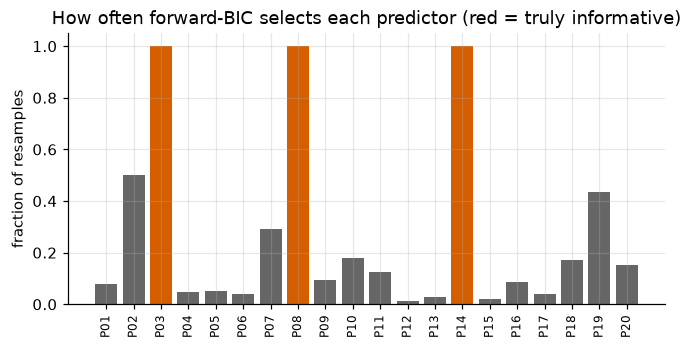

In [5]:
rng = np.random.default_rng(1)
count = np.zeros(p)
B = 150
for _ in range(B):
    idx = rng.integers(0, n, n)
    for j in stepwise(Ztr[idx], ytr[idx], "bic", "forward"):
        count[j] += 1
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(P, count / B, color=[RED if j in (2, 7, 13) else GREY for j in range(p)])
ax.set_ylabel("fraction of resamples"); ax.set_title("How often forward-BIC selects each predictor (red = truly informative)")
plt.xticks(rotation=90, fontsize=8); plt.show()

The three informative predictors are chosen almost every time, but some useless ones, for example `P02` (a neighbour of `P03`) and `P19`, enter in a large share of the resamples. The method reports one model without any sign of how uncertain that choice is. The LASSO below selects and shrinks inside a single, smooth optimisation.

# 3) The LASSO

**Objective.** Standardise each predictor (zero mean, unit standard deviation over the calibration period), centre the predictand, and minimise the least-squares error plus a penalty on the *sum of absolute values* of the coefficients:

$$\boxed{\;\hat{\boldsymbol\beta}(\lambda)=\arg\min_{\boldsymbol\beta}\; \frac{1}{2n}\sum_{t=1}^{n}\Big(y_t-\sum_{j=1}^{p} z_{tj}\beta_j\Big)^2+\lambda\sum_{j=1}^{p}|\beta_j|\;}$$

where $z_{tj}$ is the standardised predictor, $y_t$ is centred, and $\lambda\ge0$ (same units as $y$) sets the price of a non-zero coefficient. This is the LASSO (least absolute shrinkage and selection operator, Tibshirani 1996). The factor $1/2n$ is a convention that makes the formulas below tidy; other texts omit it and then their $\lambda$ differs by a factor $n$. For $\lambda=0$ we get OLS; for large $\lambda$ every coefficient is zero. In between, $\lambda$ trades fit against a small, sparse model.

**One standardised predictor: the soft threshold.** Take $p=1$. Standardisation means $\frac1n\sum z_t^2=1$. Define $\rho=\frac1n\sum z_t y_t$; since $\frac1n\sum z_t^2=1$, this $\rho$ is exactly the OLS slope. Expanding the squared error,

$$\frac{1}{2n}\sum_t (y_t-\beta z_t)^2=\frac12\Big[\frac1n\sum y_t^2\Big]-\beta\rho+\frac12\beta^2=\frac12(\beta-\rho)^2+\text{const},$$

so we must minimise $f(\beta)=\tfrac12(\beta-\rho)^2+\lambda|\beta|$. The absolute value has a kink at 0, so consider three cases.

- *$\beta>0$:* $f'(\beta)=\beta-\rho+\lambda=0$ gives $\beta=\rho-\lambda$, which is positive only if $\rho>\lambda$.
- *$\beta<0$:* $f'(\beta)=\beta-\rho-\lambda=0$ gives $\beta=\rho+\lambda$, negative only if $\rho<-\lambda$.
- *$\beta=0$:* at the kink the derivative of $\lambda|\beta|$ can be any number in $[-\lambda,\lambda]$, so $\beta=0$ is the minimum when $0\in[-\rho-\lambda,\,-\rho+\lambda]$, i.e. when $|\rho|\le\lambda$.

Together:

$$\boxed{\hat\beta = S(\rho,\lambda)=\operatorname{sign}(\rho)\,\max\big(|\rho|-\lambda,\,0\big)}$$

The OLS coefficient is **moved towards zero by $\lambda$, and stops at exactly zero** once $\lambda\ge|\rho|$. A numerical check: $\rho=0.35$ and $\lambda=0.1$ give $0.25$; $\lambda=0.35$ or $0.5$ give $0$. Ridge regression, which penalises $\lambda\beta^2/2$, gives instead $\hat\beta=\rho/(1+\lambda)$ (set the derivative $\beta-\rho+\lambda\beta$ to zero): it shrinks by a factor but never reaches zero.

**Geometry (two or more predictors).** Minimising the error subject to $\sum|\beta_j|\le t$ (an equivalent form of the same problem) means finding where an elliptical contour of the error first touches the constraint region. For the L1 penalty the region is a diamond whose *corners lie on the axes*, where some $\beta_j=0$; a contour usually touches a corner. For the L2 (ridge) penalty the region is a disc with no corners, so the touching point has all coefficients non-zero. That is the whole reason the LASSO selects and ridge does not.

**Several predictors: coordinate descent.** There is no closed form for $p>1$, but the one-dimensional result can be reused. Hold all coefficients except $\beta_j$ fixed and define the partial residual $r^{(j)}_t=y_t-\sum_{k\neq j}z_{tk}\beta_k$. The objective as a function of $\beta_j$ is $\frac1{2n}\sum_t(r^{(j)}_t-z_{tj}\beta_j)^2+\lambda|\beta_j|+\text{const}$, which is exactly the one-predictor problem with $y$ replaced by $r^{(j)}$. Hence

$$\beta_j\leftarrow S\!\big(\rho_j,\lambda\big),\qquad \rho_j=\frac1n\sum_t z_{tj}\,r^{(j)}_t .$$

Cycle through $j=1,\dots,p$ until the coefficients stop changing. Each update can only lower the (convex) objective, so the cycle converges to the minimum. The smallest $\lambda$ for which all coefficients are zero is $\lambda_{\max}=\max_j\big|\tfrac1n\sum_t z_{tj}y_t\big|$.

**Why standardise.** The penalty treats all coefficients alike. A predictor measured in large units (geopotential height in m, variance $10^3$) needs a tiny coefficient and is barely penalised; the same variable in other units would be penalised heavily. Without standardisation the selection would depend on the units. The mean and standard deviation must come from the **calibration data only** and be reused unchanged for the test or GCM data (inside cross-validation, from each training fold). The intercept is not penalised: we centre $y$ and add $\bar y$ back.

**LASSO versus ridge.** Ridge adds $\frac\lambda2\sum\beta_j^2$. It shrinks all coefficients smoothly and handles correlated predictors gracefully by sharing the weight among them, but it keeps all of them, so it does not select. The LASSO selects but, among a group of strongly correlated predictors, tends to keep one more or less arbitrarily and drop the others. A mix of the two (the elastic net) exists. Both shrink, so both coefficients are biased towards zero; the price is accepted because the variance falls more.

First the soft threshold itself, checked against a brute-force minimisation of $f(\beta)$.

max |soft-threshold - brute-force minimiser| = 1.9e-16


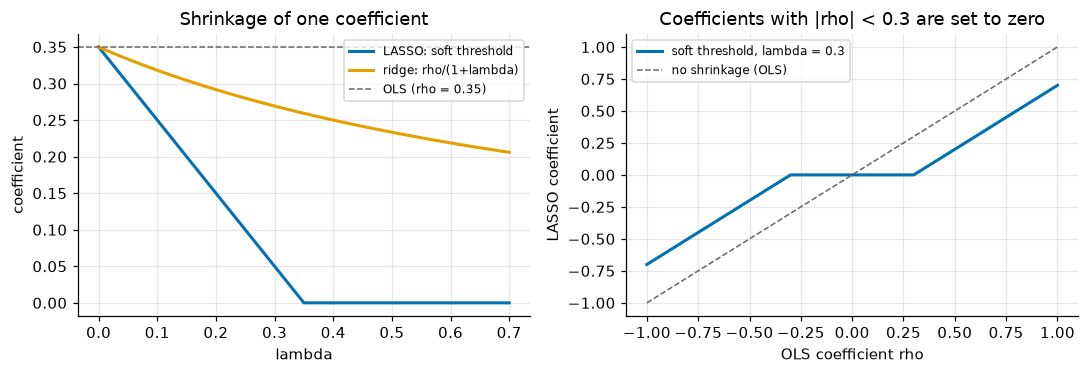

In [6]:
def soft(r, lam):
    return np.sign(r) * np.maximum(np.abs(r) - lam, 0.0)

rho0 = 0.35
lams = np.linspace(0, 0.7, 71)
grid = np.linspace(-1, 1, 20001)
brute = np.array([grid[np.argmin(0.5 * (grid - rho0)**2 + lam * np.abs(grid))] for lam in lams])
print("max |soft-threshold - brute-force minimiser| = %.1e" % np.max(np.abs(brute - soft(rho0, lams))))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(lams, soft(rho0, lams), color=BLUE, lw=2, label="LASSO: soft threshold")
ax[0].plot(lams, rho0 / (1 + lams), color=ORANGE, lw=2, label="ridge: rho/(1+lambda)")
ax[0].axhline(rho0, color=GREY, ls="--", lw=1, label="OLS (rho = 0.35)")
ax[0].set_xlabel("lambda"); ax[0].set_ylabel("coefficient"); ax[0].set_title("Shrinkage of one coefficient"); ax[0].legend(fontsize=8)
r = np.linspace(-1, 1, 201)
ax[1].plot(r, soft(r, 0.3), color=BLUE, lw=2, label="soft threshold, lambda = 0.3")
ax[1].plot(r, r, color=GREY, ls="--", lw=1, label="no shrinkage (OLS)")
ax[1].set_xlabel("OLS coefficient rho"); ax[1].set_ylabel("LASSO coefficient"); ax[1].set_title("Coefficients with |rho| < 0.3 are set to zero"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [7]:
def lasso_cd(Z, yc, lam, beta=None, tol=1e-9, maxit=2000):
    """Coordinate descent for (1/2n)||yc - Z b||^2 + lam*||b||_1.  Columns of Z standardised: (1/n) z_j.z_j = 1."""
    nn, pp = Z.shape
    beta = np.zeros(pp) if beta is None else beta.copy()
    resid = yc - Z @ beta
    for it in range(maxit):
        biggest = 0.0
        for j in range(pp):
            rho = Z[:, j] @ resid / nn + beta[j]       # (1/n) z_j . partial residual
            new = soft(rho, lam)
            if new != beta[j]:
                resid -= Z[:, j] * (new - beta[j])
                biggest = max(biggest, abs(new - beta[j])); beta[j] = new
        if biggest < tol:
            break
    return beta

yc = ytr - ytr.mean()
lam_max = np.abs(Ztr.T @ yc).max() / n
print("lambda_max = %.3f" % lam_max)
b_test = lasso_cd(Ztr, yc, 0.15)

# optimality (KKT) check: for beta_j != 0, g_j = (1/n) z_j.resid must equal lam*sign(beta_j); for beta_j = 0, |g_j| <= lam
g = Ztr.T @ (yc - Ztr @ b_test) / n
nz = b_test != 0
print("non-zero coefficients:", [P[j] for j in np.where(nz)[0]])
print("max |g_j - lam*sign(b_j)| over non-zero:  %.1e" % np.max(np.abs(g[nz] - 0.15 * np.sign(b_test[nz]))))
print("max |g_j| over zero coefficients: %.3f  (must not exceed lambda = 0.15)" % np.max(np.abs(g[~nz])))

lambda_max = 1.560
non-zero coefficients: ['P03', 'P07', 'P08', 'P14', 'P19']
max |g_j - lam*sign(b_j)| over non-zero:  3.7e-10
max |g_j| over zero coefficients: 0.138  (must not exceed lambda = 0.15)


The KKT numbers confirm that the coordinate descent solution satisfies the optimality conditions that the one-dimensional derivation implies: the correlation of each predictor with the remaining residual equals exactly $\lambda$ in size for the selected predictors, and is smaller than $\lambda$ for the discarded ones.

**The regularisation path.** Solving for a decreasing sequence of $\lambda$ (each solution as the starting point of the next, a "warm start") traces how the coefficients enter, from all zero at $\lambda_{\max}$ to nearly OLS at small $\lambda$.

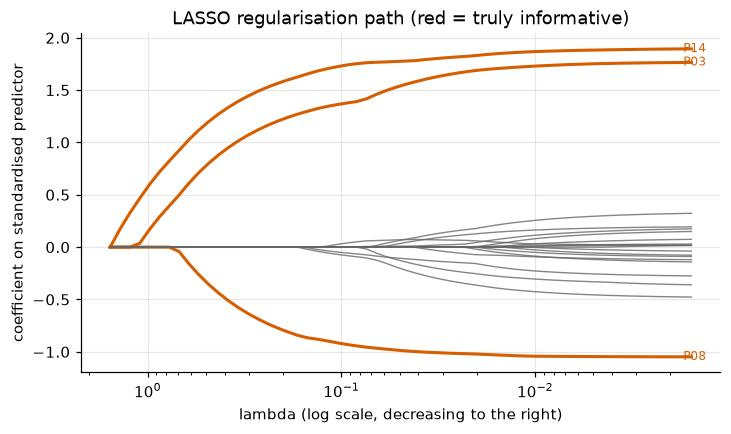

predictors with non-zero coefficient at lambda = lambda_max/3: 3, at lambda_max/100: 16


In [8]:
def lasso_path(Z, yc, lams):
    beta = np.zeros(Z.shape[1]); out = []
    for lam in lams:
        beta = lasso_cd(Z, yc, lam, beta); out.append(beta.copy())
    return np.array(out)

lam_grid = lam_max * np.logspace(0, -3, 60)
path = lasso_path(Ztr, yc, lam_grid)

fig, ax = plt.subplots(figsize=(7.5, 4))
for j in range(p):
    true = j in (2, 7, 13)
    ax.plot(lam_grid, path[:, j], color=RED if true else GREY, lw=2 if true else 0.9, alpha=1 if true else 0.8)
    if true:
        ax.text(lam_grid[-1] * 1.1, path[-1, j], P[j], color=RED, fontsize=8, va="center")
ax.set_xscale("log"); ax.invert_xaxis()
ax.set_xlabel("lambda (log scale, decreasing to the right)"); ax.set_ylabel("coefficient on standardised predictor")
ax.set_title("LASSO regularisation path (red = truly informative)")
plt.show()
print("predictors with non-zero coefficient at lambda = lambda_max/3: %d, at lambda_max/100: %d"
      % ((path[np.argmin(abs(lam_grid - lam_max/3))] != 0).sum(), (path[np.argmin(abs(lam_grid - lam_max/100))] != 0).sum()))

Reading the path from the left: the first predictors to leave zero are those most strongly related to the rainfall (here `P14` and `P03`, then `P08`). Useless predictors join only at much smaller $\lambda$ and with small coefficients, while the three informative coefficients grow towards their nearly unpenalised values. The wide range of $\lambda$ over which exactly three coefficients are non-zero is the signature of a clear-cut selection. Choosing the right $\lambda$ is the remaining problem.

# 4) Choosing $\lambda$ by cross-validation

The calibration error always prefers $\lambda\to0$, so $\lambda$ must be judged on data the fit has not seen. **$K$-fold cross-validation**:

1. split the calibration period into $K$ blocks of consecutive months (blocks, not random months, because neighbouring months are correlated; random splitting would let the model "see" the neighbours of every test month and be too optimistic);
2. for each block in turn, standardise and fit using the other $K-1$ blocks, for every $\lambda$ on the grid, and compute the mean squared error on the held-out block;
3. average the $K$ errors: $\mathrm{CV}(\lambda)=\frac1K\sum_{k}\mathrm{MSE}_k(\lambda)$, and note the standard error of the $K$ values.

Two choices are common: $\lambda_{\min}$, the minimum of the CV curve, and $\lambda_{1\mathrm{SE}}$, the *largest* $\lambda$ whose CV error is within one standard error of the minimum ("the sparsest model that is not distinguishably worse"). The second is preferred when we value a small, interpretable model.

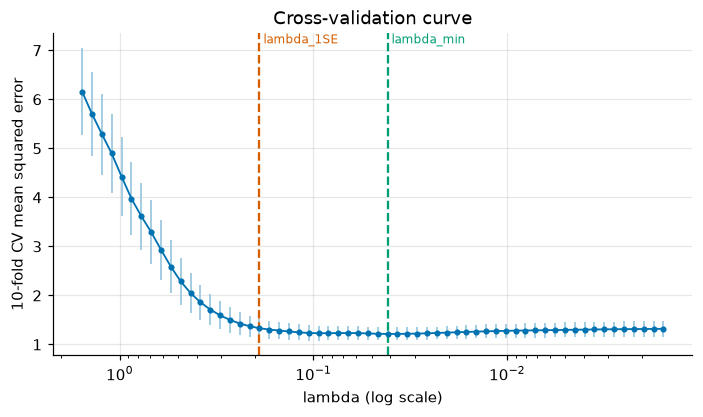

    choice  lambda  n non-zero                                                     selected  test RMSE
lambda_min   0.041          12 [P02, P03, P07, P08, P10, P11, P13, P14, P16, P18, P19, P20]   0.921998
lambda_1SE   0.190           3                                              [P03, P08, P14]   0.972636

LASSO (1SE) coefficients on standardised predictors: {'P03': np.float64(1.24), 'P08': np.float64(-0.81), 'P14': np.float64(1.6)}


In [9]:
def kfold_cv(X, y, lams, K=10):
    """Blocked K-fold CV for the LASSO. Standardisation is redone inside every training fold (no leakage)."""
    folds = np.array_split(np.arange(len(y)), K)
    err = np.zeros((K, len(lams)))
    for k, test in enumerate(folds):
        train = np.setdiff1d(np.arange(len(y)), test)
        m, s = X[train].mean(0), X[train].std(0)
        ym = y[train].mean()
        B = lasso_path((X[train] - m) / s, y[train] - ym, lams)
        Zt = (X[test] - m) / s
        err[k] = [np.mean((y[test] - ym - Zt @ b)**2) for b in B]
    return err

err = kfold_cv(Xtr, ytr, lam_grid, K=10)
cv, cv_se = err.mean(0), err.std(0, ddof=1) / np.sqrt(err.shape[0])
i_min = int(np.argmin(cv))
i_1se = int(np.where(cv <= cv[i_min] + cv_se[i_min])[0][0])     # grid runs from large to small lambda
lam_min, lam_1se = lam_grid[i_min], lam_grid[i_1se]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.errorbar(lam_grid, cv, yerr=cv_se, color=BLUE, ecolor="#9ecae1", marker="o", ms=3, lw=1.2)
ax.axvline(lam_min, color=GREEN, ls="--"); ax.axvline(lam_1se, color=RED, ls="--")
ax.text(lam_min, ax.get_ylim()[1], " lambda_min", color=GREEN, va="top", fontsize=8)
ax.text(lam_1se, ax.get_ylim()[1], " lambda_1SE", color=RED, va="top", fontsize=8)
ax.set_xscale("log"); ax.invert_xaxis(); ax.set_xlabel("lambda (log scale)"); ax.set_ylabel("10-fold CV mean squared error")
ax.set_title("Cross-validation curve")
plt.show()

def lasso_fit_final(lam):
    beta = lasso_cd(Ztr, yc, lam, lasso_path(Ztr, yc, lam_grid[lam_grid >= lam])[-1])
    return beta
rows = []
for name, lam in (("lambda_min", lam_min), ("lambda_1SE", lam_1se)):
    beta = lasso_fit_final(lam)
    pred = ytr.mean() + Zte @ beta
    rows.append([name, round(lam, 3), int((beta != 0).sum()), [P[j] for j in np.where(beta != 0)[0]], rmse(pred, yte)])
print(pd.DataFrame(rows, columns=["choice", "lambda", "n non-zero", "selected", "test RMSE"]).to_string(index=False))
beta_1se = lasso_fit_final(lam_1se); sel_lasso = list(np.where(beta_1se != 0)[0])
print("\nLASSO (1SE) coefficients on standardised predictors:", dict(zip([P[j] for j in sel_lasso], beta_1se[sel_lasso].round(2))))

The $\lambda_{1\mathrm{SE}}$ rule keeps (essentially) only the informative predictors. Their coefficients are *smaller* than the OLS values because the penalty shrinks them (a consequence of the soft threshold: every non-zero coefficient is pulled in by about $\lambda$). A common remedy is to refit ordinary least squares on the selected predictors afterwards. The selection step then uses the LASSO, and the final coefficients are not shrunk. Whether this helps in prediction depends on the problem, so check it on validation data.

# 5) A nonlinear model: the artificial neural network

All the models so far are straight lines in the predictors, but `P14` acts through a saturating curve. A **feed-forward neural network with one hidden layer** builds a nonlinear function from $m$ smooth steps. For one month with predictors $\mathbf x=(x_1,\dots,x_p)$:

$$a_j=\sum_{i=1}^{p}W_{ij}\,x_i+b_j,\qquad h_j=\tanh(a_j),\qquad \hat y=c+\sum_{j=1}^{m}v_j\,h_j,\qquad j=1,\dots,m .$$

Here $a_j$ is the input of hidden unit $j$ (a weighted sum, as in a regression), $h_j\in(-1,1)$ its output, $W_{ij}$, $b_j$ the input weights and biases, $v_j$, $c$ the output weights and bias. A unit with $W_{ij}$ large behaves like a switch, with $W_{ij}$ small like a gentle curve. If $\tanh$ were replaced by the identity, $\hat y$ would be a linear function of $\mathbf x$, so the network contains linear regression as a special case. The number of parameters is $(p+2)m+1$.

**Loss.** For $n$ training months with errors $e_t=\hat y_t-y_t$ we minimise the mean squared error (with a $\tfrac12$ that cancels the 2 in the derivative):

$$L=\frac1{2n}\sum_{t=1}^{n}e_t^2 .$$

**Backpropagation = the chain rule.** We need $\partial L/\partial\theta$ for every parameter. Work backwards from the loss.

1. $\dfrac{\partial L}{\partial\hat y_t}=\dfrac{e_t}{n}$.
2. Output layer: $\hat y_t=c+\sum_j v_jh_{tj}$, so $\dfrac{\partial L}{\partial v_j}=\dfrac1n\sum_t e_t\,h_{tj}$ and $\dfrac{\partial L}{\partial c}=\dfrac1n\sum_t e_t$.
3. Through the hidden unit: $\dfrac{\partial\hat y_t}{\partial h_{tj}}=v_j$, and since $\dfrac{d}{da}\tanh a=1-\tanh^2 a$ we have $\dfrac{\partial h_{tj}}{\partial a_{tj}}=1-h_{tj}^2$. Define the "error signal" arriving at hidden unit $j$ in month $t$:
$$\delta_{tj}\equiv\frac{\partial L}{\partial a_{tj}}=\frac{e_t}{n}\,v_j\,\big(1-h_{tj}^2\big).$$
4. Input layer: $a_{tj}=\sum_iW_{ij}x_{ti}+b_j$, so
$$\frac{\partial L}{\partial W_{ij}}=\sum_t\delta_{tj}\,x_{ti},\qquad \frac{\partial L}{\partial b_j}=\sum_t\delta_{tj}.$$

(For a sigmoid unit $h=1/(1+e^{-a})$ the only change is $dh/da=h(1-h)$.) Gradient descent then repeats $\theta\leftarrow\theta-\eta\,\partial L/\partial\theta$ with a small learning rate $\eta$. In matrix form, with $H$ the $n\times m$ matrix of $h_{tj}$ and $\boldsymbol\delta=\mathbf e/n$: $\nabla_{\mathbf v}L=H^{\!\top}\boldsymbol\delta$ and $\nabla_{W}L=X^{\!\top}\big[(\boldsymbol\delta\mathbf v^{\!\top})\odot(1-H^2)\big]$, which is what the code below does. A **numerical check** is built in: compare one analytic derivative with $\big(L(\theta+\epsilon)-L(\theta-\epsilon)\big)/2\epsilon$.

**Practical points.** (i) Standardise inputs and the predictand, so that tanh works in its sensitive range. (ii) Start from small *random* weights; with identical weights all hidden units would stay identical (symmetry). (iii) The loss surface has many local minima, so different random starts give different networks; average a few. (iv) **Overfitting control:** hold out the last part of the calibration period as a validation set, watch the validation loss as training proceeds, and keep the weights from the epoch where it was lowest (**early stopping**). Training loss keeps falling; validation loss turns up when the network starts to fit noise. The number of hidden units $m$ is a second control; fewer units mean a smoother, more cautious function.

In [10]:
class ANN:
    """One hidden layer, tanh units, linear output. Trained by full-batch gradient descent."""
    def __init__(self, p_in, m, rng, scale=0.5):
        self.W = rng.standard_normal((p_in, m)) * scale / np.sqrt(p_in); self.b = np.zeros(m)
        self.v = rng.standard_normal(m) * scale / np.sqrt(m);             self.c = 0.0
    def forward(self, X):
        H = np.tanh(X @ self.W + self.b)
        return H, H @ self.v + self.c
    def loss(self, X, y):
        return 0.5 * np.mean((self.forward(X)[1] - y)**2)
    def grads(self, X, y):
        H, yhat = self.forward(X)
        delta = (yhat - y) / len(y)                       # dL/dyhat
        dv, dc = H.T @ delta, delta.sum()
        G = np.outer(delta, self.v) * (1 - H**2)          # dL/da  (n x m)
        return X.T @ G, G.sum(0), dv, dc                  # dW, db, dv, dc
    def get(self): return [self.W.copy(), self.b.copy(), self.v.copy(), self.c]
    def set(self, s): self.W, self.b, self.v, self.c = [np.copy(a) for a in s]

def train(net, Xa, ya, Xv, yv, lr=0.1, epochs=5000, patience=300):
    """Gradient descent with early stopping on the validation set; restores the best weights."""
    hist, best = [], (np.inf, net.get(), 0)
    for ep in range(epochs):
        dW, db, dv, dc = net.grads(Xa, ya)
        net.W -= lr * dW; net.b -= lr * db; net.v -= lr * dv; net.c -= lr * dc
        hist.append((net.loss(Xa, ya), net.loss(Xv, yv)))
        if hist[-1][1] < best[0]:
            best = (hist[-1][1], net.get(), ep)
        elif ep - best[2] > patience:
            break
    net.set(best[1])
    return np.array(hist), best[2]

# gradient check on random weights: analytic dL/dW[0,0] against a central finite difference
chk = ANN(3, 4, np.random.default_rng(5)); Xc = np.random.default_rng(6).standard_normal((20, 3)); yc_ = np.random.default_rng(7).standard_normal(20)
eps = 1e-6; analytic = chk.grads(Xc, yc_)[0][0, 0]
chk.W[0, 0] += eps; Lp = chk.loss(Xc, yc_); chk.W[0, 0] -= 2 * eps; Lm = chk.loss(Xc, yc_); chk.W[0, 0] += eps
print("dL/dW[0,0]: backprop %.8f, finite difference %.8f" % (analytic, (Lp - Lm) / (2 * eps)))

dL/dW[0,0]: backprop 0.03535637, finite difference 0.03535637


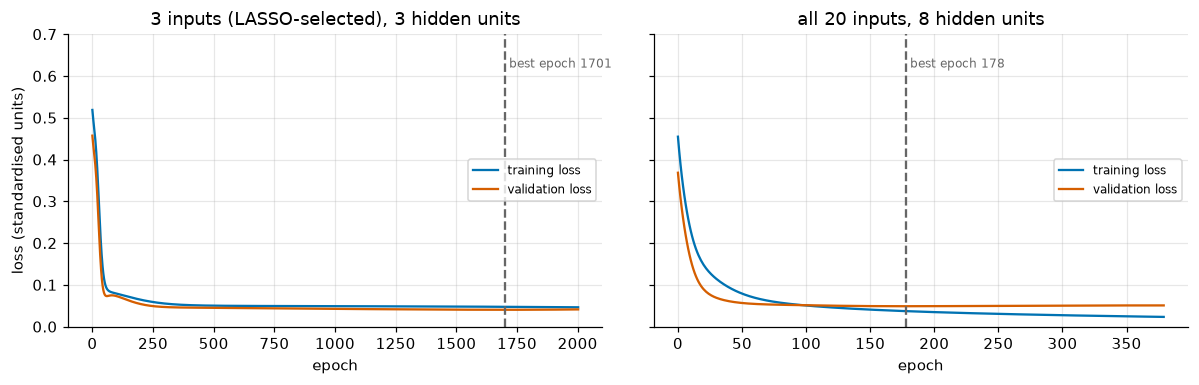

parameters: 16 (small network) and 177 (large network); training months used: 90


In [11]:
# Use the predictors chosen by the LASSO (1SE) as inputs; last 30 calibration months = validation set for early stopping
cols = sel_lasso
nv = 30
ya, yv = ytr[:-nv], ytr[-nv:]
ym, ys = ya.mean(), ya.std()
Xa, Xv = Ztr[:-nv][:, cols], Ztr[-nv:][:, cols]

def fit_ann(Xa, ya, Xv, yv, m, seeds=range(5), **kw):
    """Several random starts; keep the one with the lowest validation loss."""
    best = None
    for s in seeds:
        net = ANN(Xa.shape[1], m, np.random.default_rng(s))
        hist, ep = train(net, Xa, (ya - ym) / ys, Xv, (yv - ym) / ys, **kw)
        if best is None or hist[ep, 1] < best[2][best[1], 1]:
            best = (net, ep, hist)
    return best

net3, ep3, hist3 = fit_ann(Xa, ya, Xv, yv, m=3)                                   # inputs chosen by the LASSO, 3 hidden units
netA, epA, histA = fit_ann(Ztr[:-nv], ya, Ztr[-nv:], yv, m=8, patience=200)        # all 20 inputs, 8 hidden units
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a_, h_, e_, ttl in ((ax[0], hist3, ep3, "3 inputs (LASSO-selected), 3 hidden units"), (ax[1], histA, epA, "all 20 inputs, 8 hidden units")):
    a_.plot(h_[:, 0], color=BLUE, label="training loss"); a_.plot(h_[:, 1], color=RED, label="validation loss")
    a_.axvline(e_, color=GREY, ls="--"); a_.text(e_, 0.62, " best epoch %d" % e_, fontsize=8, color=GREY)
    a_.set_xlabel("epoch"); a_.set_title(ttl); a_.legend(fontsize=8, loc="center right")
ax[0].set_ylabel("loss (standardised units)"); ax[0].set_ylim(0, 0.7)
plt.tight_layout(); plt.show()
print("parameters: %d (small network) and %d (large network); training months used: %d" % ((len(cols) + 2) * 3 + 1, (p + 2) * 8 + 1, len(ya)))

# 6) Comparing the four models on the held-out period

Four models are now fitted on the same 120 calibration months and judged on the 120 test months that none of them has seen: OLS with all 20 predictors, forward-BIC stepwise OLS, the LASSO with $\lambda_{1\mathrm{SE}}$, and the one-hidden-layer network on the LASSO-selected predictors. (A larger network with 8 hidden units on all 20 predictors is added for contrast.) The LASSO selection uses calibration data only, so there is no leakage into the test period.

                               model  predictors  test RMSE  test R2
              OLS, all 20 predictors          20      1.015    0.828
             stepwise (BIC, forward)           5      0.958    0.847
                  LASSO (lambda_1SE)           3      0.973    0.842
ANN, 3 hidden, LASSO-selected inputs           3      0.944    0.851
        ANN, 8 hidden, all 20 inputs          20      1.020    0.826
noise floor (RMSE of the true function):  0.80


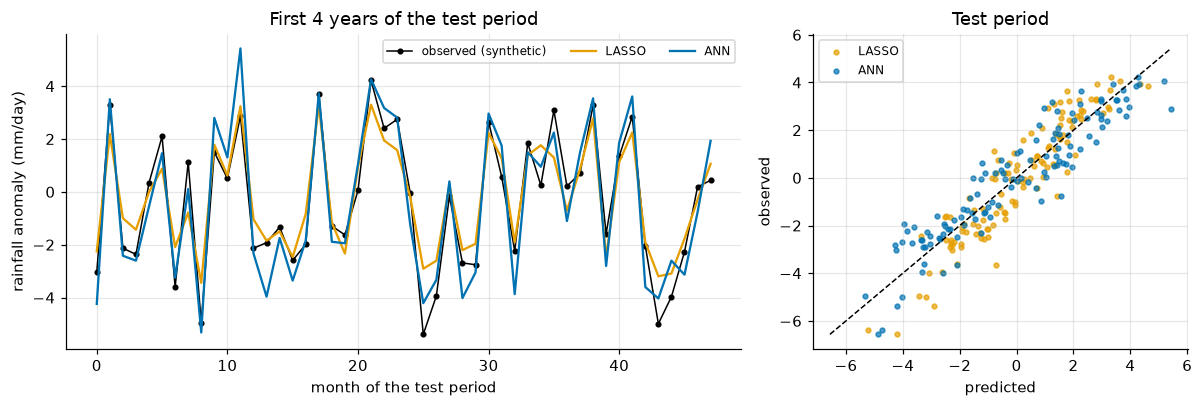

In [12]:
res = []
b_all = ols(Ztr, ytr);                         pred_all = predict_ols(b_all, Zte)
b_sw = ols(Ztr[:, sel_bic], ytr);              pred_sw = predict_ols(b_sw, Zte[:, sel_bic])
pred_lasso = ytr.mean() + Zte @ beta_1se
pred_ann = net3.forward(Zte[:, cols])[1] * ys + ym

pred_ann_all = netA.forward(Zte)[1] * ys + ym

for name, pr, k in (("OLS, all 20 predictors", pred_all, 20), ("stepwise (BIC, forward)", pred_sw, len(sel_bic)),
                    ("LASSO (lambda_1SE)", pred_lasso, len(sel_lasso)), ("ANN, 3 hidden, LASSO-selected inputs", pred_ann, len(cols)),
                    ("ANN, 8 hidden, all 20 inputs", pred_ann_all, 20)):
    res.append([name, k, rmse(pr, yte), 1 - np.sum((pr - yte)**2) / np.sum((yte - yte.mean())**2)])
print(pd.DataFrame(res, columns=["model", "predictors", "test RMSE", "test R2"]).round(3).to_string(index=False))
print("noise floor (RMSE of the true function):  0.80")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.8, 1]})
t = np.arange(48)
ax[0].plot(t, yte[:48], "k.-", lw=1, label="observed (synthetic)")
ax[0].plot(t, pred_lasso[:48], color=ORANGE, lw=1.5, label="LASSO"); ax[0].plot(t, pred_ann[:48], color=BLUE, lw=1.5, label="ANN")
ax[0].set_xlabel("month of the test period"); ax[0].set_ylabel("rainfall anomaly (mm/day)"); ax[0].set_title("First 4 years of the test period"); ax[0].legend(fontsize=8, ncol=3)
ax[1].scatter(pred_lasso, yte, s=10, color=ORANGE, alpha=0.7, label="LASSO"); ax[1].scatter(pred_ann, yte, s=10, color=BLUE, alpha=0.7, label="ANN")
lim = [min(yte.min(), pred_ann.min()), max(yte.max(), pred_ann.max())]; ax[1].plot(lim, lim, "k--", lw=1)
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("observed"); ax[1].set_title("Test period"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

OLS with all 20 predictors is the weakest of the linear models; stepwise and the LASSO improve on it by dropping useless columns. The small network on the selected predictors is slightly better still, but that is **only because we built a saturating relation into the data**; had the truth been linear, it would have had nothing to add and a little more variance to pay for. Be careful with small differences: 120 test months carry sampling noise, and a gap of 0.03 mm/day in RMSE would change with another random seed for the data. The more important point is that the large network on all 20 inputs does not beat the small one on the selected inputs: selection and a small network work together. The early-stopping plot above shows why: the large network starts to overfit after very few epochs.

# 7) When is a neural network worth it, and the extrapolation risk

The test period above has the same statistics as the calibration period. Climate-change downscaling asks something harder: apply the model to GCM predictors that lie partly *outside* the range seen in calibration. The next cell asks both models what they predict for `P14` far outside its calibration range, with everything else at zero. In the synthetic truth, the 0.3 slope that persists beyond saturation is a stand-in for a physical effect (for example, warmer air holding more moisture) that the calibration period only partly sampled.

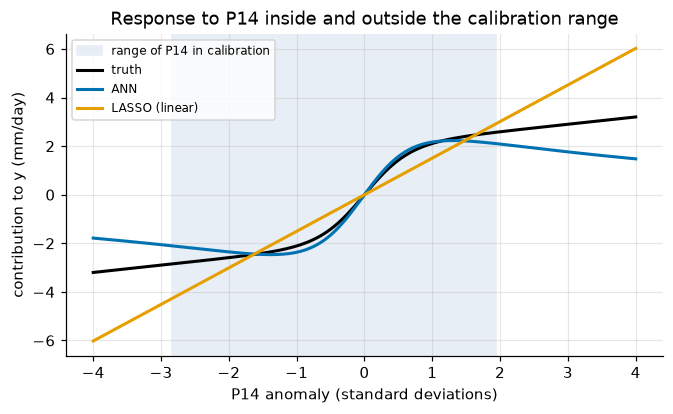

In [13]:
j14 = P.index("P14"); x = np.linspace(-4, 4, 161)
truth = 2 * np.tanh(1.5 * x) + 0.3 * x                       # contribution of P14 in the data recipe
Xg = np.zeros((len(x), len(cols)))                            # all other predictors at their calibration mean
Xg[:, cols.index(j14)] = (x - mu[j14]) / sd[j14]              # standardise with calibration statistics
ann_curve = net3.forward(Xg)[1] * ys + ym
lin_curve = Xg @ beta_1se[cols] + ym
i0 = len(x) // 2                                              # x = 0: show all curves relative to the value there
truth, ann_curve, lin_curve = truth - truth[i0], ann_curve - ann_curve[i0], lin_curve - lin_curve[i0]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.axvspan(Xtr[:, j14].min(), Xtr[:, j14].max(), color="#e8eef5", label="range of P14 in calibration")
ax.plot(x, truth, "k", lw=2, label="truth"); ax.plot(x, ann_curve, color=BLUE, lw=2, label="ANN"); ax.plot(x, lin_curve, color=ORANGE, lw=2, label="LASSO (linear)")
ax.set_xlabel("P14 anomaly (standard deviations)"); ax.set_ylabel("contribution to y (mm/day)")
ax.set_title("Response to P14 inside and outside the calibration range"); ax.legend(fontsize=8)
plt.show()

Inside the shaded range, the network follows the saturating truth and the straight line does not. Outside it, the tanh units level off and the fitted curve is free to do anything (here it bends slightly downward), while the truth keeps rising slowly; the linear model keeps rising but far too steeply, because its slope was fitted to the steep middle part of the curve. Neither is reliable out of range, and the network gives no warning. Honest guidance:

**A network can help when**
- the predictor&ndash;predictand relation is clearly nonlinear (saturation, thresholds, interactions between predictors) and a plot or a test on held-out data shows that a linear model leaves structure in the residuals;
- the predictand is not Gaussian. Daily rainfall is zero on most days and strongly skewed on the others. A network with a squared-error loss still estimates only a smooth conditional mean and, like regression, deflates the variance (Lecture 19). The usual remedy is to change the **output and the loss**: a sigmoid output with a cross-entropy loss for rain occurrence, and a separate model (for example for a gamma-distributed amount) for rain on wet days. Rare extremes are a weak point because the training data hold few of them;
- there is enough data: a daily record gives thousands of cases; 30 years of monthly values give a few hundred, and then a network of more than a handful of hidden units has more parameters than the data can support.

**Cautions**
- *Extrapolation.* A bounded activation cannot represent a trend it has not seen. Under climate change that is the central risk of any purely statistical method, and it is sharper for flexible ones. Mitigations: use predictors that physically drive the predictand and are well simulated by the GCM, check the range of the GCM predictors against the calibration range, validate on a warm or dry period held out *by climate state* rather than at random, and compare with a simpler linear baseline (if the two disagree strongly in the future, ask why).
- *Variability between fits.* Different random starts give different networks; use an ensemble of several and look at their spread.
- *Complexity is not accuracy.* A network that beats a regression by a few percent on a test period may not be worth the loss of interpretability. Always report the linear baseline next to it.

# 8) Companion spreadsheet

The workbook `data/downscaling/lec20/lec20_worked_examples.xlsx` repeats three calculations with live formulas on a small synthetic table of 30 months (`lec20_toy_data.csv`: predictors `x1`..`x4`, predictand `y`; true model $y=1.2x_1-0.8x_2+$ noise). Blue cells are inputs, black cells are formulas.

| Sheet | What it shows |
|:--|:--|
| `Lasso_1D` | one standardised predictor, a table over $\lambda$: OLS slope, LASSO slope $=\operatorname{sign}(\rho)\max(|\rho|-\lambda,0)$, ridge slope, exact zeros, and a check that the objective is lowest at the soft-threshold value |
| `AIC_BIC` | nested models from LINEST (`INDEX(LINEST(y,X,TRUE,TRUE),5,2)` is SSE): SSE, adjusted R$^2$, AIC, BIC, and the $t$ statistics and p-values of the full model |
| `NN_Tiny` | a network with two inputs and two tanh hidden units on six rows: forward pass, loss, every backpropagation term in its own column, and three gradient-descent steps, plus a finite-difference check of one gradient |

The code below recomputes the same quantities in Python from the same CSV, so you can compare it with the sheet.

In [14]:
def make_toy():
    """Recipe of the 30-month table used in the spreadsheet (fallback if the CSV cannot be read)."""
    rng = np.random.default_rng(20); m = 30
    x1 = rng.standard_normal(m); x2 = rng.standard_normal(m)
    x3 = 0.5 * x1 + np.sqrt(0.75) * rng.standard_normal(m); x4 = rng.standard_normal(m)
    y = 1.2 * x1 - 0.8 * x2 + 0.7 * rng.standard_normal(m)
    return pd.DataFrame({"obs": np.arange(1, m + 1), "x1": x1, "x2": x2, "x3": x3, "x4": x4, "y": y}).round(3)

toy = read_csv("lec20_toy_data.csv")
if toy is None:
    toy = make_toy()
xt = toy[["x1", "x2", "x3", "x4"]].values; yt = toy["y"].values; nt = len(yt)

# AIC_BIC sheet
rows = []
for k, name in enumerate(["intercept only", "x1", "x1, x2", "x1, x2, x3", "x1, x2, x3, x4"]):
    s = sse(xt[:, :k], yt); kk = k + 1
    rows.append([name, s, nt * np.log(s / nt) + 2 * kk, nt * np.log(s / nt) + kk * np.log(nt)])
aic_tab = pd.DataFrame(rows, columns=["model", "SSE", "AIC", "BIC"])
print(aic_tab.round(3).to_string(index=False))
print("best by AIC:", aic_tab.model[aic_tab.AIC.idxmin()], "| best by BIC:", aic_tab.model[aic_tab.BIC.idxmin()])

# Lasso_1D sheet
z1 = (xt[:, 0] - xt[:, 0].mean()) / xt[:, 0].std(); y1 = yt - yt.mean(); rho1 = np.mean(z1 * y1)
print("\nLasso_1D: rho = %.4f" % rho1)
print(pd.DataFrame({"lambda": np.arange(16) * 0.1, "LASSO": soft(rho1, np.arange(16) * 0.1), "ridge": rho1 / (1 + np.arange(16) * 0.1)}).round(4).T.to_string(header=False))

# NN_Tiny sheet: 2 inputs, 2 tanh units, first six rows, learning rate 0.3, three steps
X6, y6 = xt[:6, :2], yt[:6]
net = ANN(2, 2, np.random.default_rng(0))
net.W = np.array([[0.5, -0.3], [-0.4, 0.6]]); net.b = np.array([0.1, -0.1]); net.v = np.array([0.4, -0.5]); net.c = 0.0
losses = []
for step in range(4):
    losses.append(net.loss(X6, y6))
    dW, db, dv, dc = net.grads(X6, y6)
    net.W -= 0.3 * dW; net.b -= 0.3 * db; net.v -= 0.3 * dv; net.c -= 0.3 * dc
print("\nNN_Tiny loss at steps 0..3:", np.round(losses, 4))

         model    SSE     AIC     BIC
intercept only 64.965  25.180  26.581
            x1 34.999   8.623  11.426
        x1, x2 11.141 -23.717 -19.514
    x1, x2, x3 10.415 -23.737 -18.132
x1, x2, x3, x4  9.530 -24.403 -17.397
best by AIC: x1, x2, x3, x4 | best by BIC: x1, x2

Lasso_1D: rho = 0.9994
lambda  0.0000  0.1000  0.2000  0.3000  0.4000  0.5000  0.6000  0.7000  0.8000  0.9000  1.0000  1.1000  1.2000  1.3000  1.4000  1.5000
LASSO   0.9994  0.8994  0.7994  0.6994  0.5994  0.4994  0.3994  0.2994  0.1994  0.0994  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
ridge   0.9994  0.9086  0.8329  0.7688  0.7139  0.6663  0.6247  0.5879  0.5552  0.5260  0.4997  0.4759  0.4543  0.4345  0.4164  0.3998

NN_Tiny loss at steps 0..3: [0.6449 0.5001 0.3958 0.3196]


# Summary

- Many predictors, few months and correlated columns lead to overfitting and unstable coefficients: the calibration error always falls, the test error does not.
- **Stepwise regression** adds or removes one predictor at a time by p-value, AIC $=n\ln(\mathrm{SSE}/n)+2k$ or BIC $=n\ln(\mathrm{SSE}/n)+k\ln n$. BIC chooses smaller models. It is greedy, its statistics are optimistic and its choice is unstable under resampling.
- The **LASSO** minimises $\frac1{2n}\|y-Z\beta\|^2+\lambda\|\beta\|_1$. For one standardised predictor the answer is the soft threshold $\operatorname{sign}(\rho)\max(|\rho|-\lambda,0)$: shrinkage plus exact zeros, because the L1 ball has corners on the axes. Coordinate descent applies this update to one coefficient at a time on the partial residual.
- Standardise with calibration-period statistics (the penalty depends on the scale). Choose $\lambda$ by blocked $K$-fold cross-validation, with $\lambda_{\min}$ or the sparser $\lambda_{1\mathrm{SE}}$. Ridge shrinks but never selects.
- A one-hidden-layer **neural network** $\hat y=c+\sum_jv_j\tanh(\sum_iW_{ij}x_i+b_j)$ is trained by backpropagation (the chain rule: $\delta_{tj}=\frac{e_t}{n}v_j(1-h_{tj}^2)$), with early stopping on a validation set.
- A network can beat a linear model for nonlinear or non-Gaussian predictands, but it does not extrapolate: outside the calibration range its predictions flatten. Always compare with a linear baseline and test on a climate state held out from calibration.

# Check your understanding

1. A standardised predictor has OLS slope $\rho=0.35$. What are the LASSO and ridge coefficients for $\lambda=0.1$, $0.35$ and $0.5$?
2. A colleague standardises all predictors using the mean and standard deviation of the **whole** record (calibration plus test) before choosing $\lambda$. What is wrong with that, and why does it matter more in downscaling than in the usual machine-learning setting?
3. For $n=120$, by what percentage must adding one predictor reduce SSE for AIC to keep it? For BIC? (Use $\mathrm{SSE}_{\text{new}}/\mathrm{SSE}_{\text{old}}=e^{-2/n}$ and $e^{-\ln n/n}$.)
4. If the activation function of a network is the identity, what model do you get, and why is backpropagation then not needed?
5. A network downscaling monthly rainfall is calibrated on 1990&ndash;2010 and applied to GCM predictors for 2080&ndash;2100, when humidity is out of the calibration range. Describe two checks you would carry out before trusting its projections.

# Try it yourself

- Change `noise` in `make_data` from 0.8 to 2.0. What happens to $\lambda_{1\mathrm{SE}}$ and to the number of selected predictors?
- Replace the blocked folds in `kfold_cv` by random folds. Does the CV curve move? (Hint: there is no autocorrelation in this synthetic series; what would change with real monthly data?)
- Refit OLS on the LASSO-selected predictors and compare its test RMSE with the shrunken LASSO coefficients.
- Train the network with 1, 3, 10 and 30 hidden units and no early stopping (`patience=10**9`). Plot the test RMSE against $m$.
- In the spreadsheet, change the lambda step in `Lasso_1D` and the learning rate in `NN_Tiny` (try 1.5) and describe what happens.

```{note} Sources
The methods follow Chapter 5 of Lee, T., & Singh, V. P. (2019). *Statistical Downscaling for Hydrological and Environmental Applications*. CRC Press: Section 5.2 (predictor selection: stepwise regression and the LASSO), Section 5.3 (artificial neural networks) and Section 5.4 (summary). The equations in this lecture were derived afresh for CE524 in our own notation and normalisation (for example the $1/2n$ factor in the LASSO objective, so that $\lambda$ here is not the same number as in the book), and the data, code and figures are our own.

**Method papers.** Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. *Journal of the Royal Statistical Society, Series B*, 58(1), 267&ndash;288. Akaike's and Schwarz's criteria (AIC, BIC) are standard results found in any regression text; the Gaussian-likelihood derivation above is the textbook one.

All data in this notebook and in the companion workbook are synthetic. Text under CC BY-SA 4.0, code additionally under the MIT License; full attribution in [CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```